# 06.3 — Training a Tiny GPT

Everything from folders 02–06 put together: a decoder-only transformer (the same design as GPT-2), trained from scratch on Shakespeare
with a BPE tokenizer, AdamW, warm-up + cosine schedule and gradient clipping, then used to generate text with greedy, temperature, top-k and top-p sampling.

## What's in this notebook

- 1\. What a GPT learns: next-token prediction
- 2\. The data: tokens and training windows
- 3\. The model
- 4\. A sanity check before training
- 5\. Training: AdamW, warm-up, cosine, clipping
- 6\. Learning curves, perplexity and overfitting
- 7\. Generating text: greedy, temperature, top-k, top-p
- 8\. Saving and loading the model
- 9\. From this toy to a real LLM
- 10\. Trade-offs
- 11\. Interview questions
- 12\. In my own words

In [1]:
import copy
import hashlib
import math
import time
import urllib.request
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers
from torch import nn

DATA = Path("../data/shakespeare/input.txt")
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
MODEL_DIR = Path("../models")
if not DATA.exists():
    DATA.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, DATA)
assert hashlib.md5(DATA.read_bytes()).hexdigest() == "6fb458f1232090904fb40fe944165e91", "unexpected file"
text = DATA.read_text()
split = int(len(text) * 0.9)
train_text, val_text = text[:split], text[split:]


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


device = get_device()
print("device:", device, f"| {len(train_text):,} training characters, {len(val_text):,} validation characters")

device: mps | 1,003,854 training characters, 111,540 validation characters


# 1. WHAT A GPT LEARNS: NEXT-TOKEN PREDICTION

A GPT is a stack of transformer blocks with a **causal mask** (06.2), trained on one task: **predict the next token**.

```text
text:      To  be ,  or  not  to  be
input:     To  be ,  or  not  to          the window, minus its last token
target:    be  ,  or not  to  be          the same window shifted left by one
```

- Thanks to the causal mask, every position in a window is a separate training example (predict token t+1 from tokens 0..t), all computed in one forward pass.
- The loss is the average **cross-entropy**, `−log p(correct next token)`. **Perplexity** = e^loss: roughly, how many tokens the model is choosing between at each step.
- During training the model always sees the *true* previous tokens (**teacher forcing**); during generation it sees its own predictions,
  so early mistakes can compound (**exposure bias**).
- No labels are needed: any text is training data. That is what made huge pre-training possible.

# 2. THE DATA: TOKENS AND TRAINING WINDOWS

A byte-level BPE tokenizer with 2,048 tokens, trained on the training text only (06.1 section 9). Training batches are random windows of 128 tokens.

In [2]:
tokenizer = Tokenizer(models.BPE())
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=2048, special_tokens=["<|endoftext|>"],
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
tokenizer.train_from_iterator(train_text.splitlines(keepends=True), trainer)

train_ids = torch.tensor(tokenizer.encode(train_text).ids)
val_ids = torch.tensor(tokenizer.encode(val_text).ids)
print(f"vocabulary {tokenizer.get_vocab_size():,} | train {len(train_ids):,} tokens, validation {len(val_ids):,} tokens "
      f"({len(train_text) / len(train_ids):.2f} characters per token)")

CONTEXT, BATCH = 128, 32


def get_batch(ids: torch.Tensor, generator: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    """BATCH random windows: x is a window, y is the same window shifted by one token."""
    starts = torch.randint(0, len(ids) - CONTEXT - 1, (BATCH,), generator=generator)
    x = torch.stack([ids[s:s + CONTEXT] for s in starts])
    y = torch.stack([ids[s + 1:s + CONTEXT + 1] for s in starts])
    return x.to(device), y.to(device)


x, y = get_batch(train_ids, torch.Generator().manual_seed(0))
print("batch:", tuple(x.shape), "| first input tokens: ", x[0, :8].tolist(), "\n                    first target tokens:", y[0, :8].tolist())
print("decoded input window:", repr(tokenizer.decode(x[0, :24].tolist())))

vocabulary 2,048 | train 346,862 tokens, validation 43,559 tokens (2.89 characters per token)
batch: (32, 128) | first input tokens:  [818, 26, 199, 41, 732, 419, 12, 1442] 
                    first target tokens: [26, 199, 41, 732, 419, 12, 1442, 12]
decoded input window: 'MENENIUS:\nI tell thee, fellow,\nThe general is my lover: I have been\nThe book'


# 3. THE MODEL

The same layout as GPT-2, scaled down:
- token embeddings + learned position embeddings;
- 6 pre-norm transformer blocks (06.2), using `F.scaled_dot_product_attention(is_causal=True)`, the fused kernel, instead of the hand-written loop;
- dropout on the residual branches only; like many modern LLMs, no dropout on the attention weights;
- a final LayerNorm and a linear **language-model head** that turns each position's vector into scores over the vocabulary;
- **weight tying:** the head reuses the token-embedding matrix, which saves parameters and usually helps;
- weights initialized with a small normal distribution (std 0.02), as in GPT-2.

In [3]:
@dataclass
class GPTConfig:
    vocab_size: int = 2048
    context: int = CONTEXT
    d_model: int = 256
    n_layers: int = 6
    n_heads: int = 8
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.n_heads = cfg.n_heads
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model)        # Q, K and V in one matrix multiply
        self.proj = nn.Linear(cfg.d_model, cfg.d_model)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        split = lambda t: t.view(B, T, self.n_heads, D // self.n_heads).transpose(1, 2)
        out = F.scaled_dot_product_attention(split(q), split(k), split(v), is_causal=True)   # no dropout on attention weights
        return self.proj(out.transpose(1, 2).reshape(B, T, D))


class Block(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg)
        self.ff = nn.Sequential(nn.Linear(cfg.d_model, 4 * cfg.d_model), nn.GELU(), nn.Linear(4 * cfg.d_model, cfg.d_model))
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        x = x + self.drop(self.attn(self.norm1(x)))
        return x + self.drop(self.ff(self.norm2(x)))


class GPT(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.tok = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.pos = nn.Embedding(cfg.context, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.norm = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok.weight                         # weight tying
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, ids):
        x = self.drop(self.tok(ids) + self.pos(torch.arange(ids.shape[1], device=ids.device)))
        for block in self.blocks:
            x = block(x)
        return self.head(self.norm(x))                             # (batch, tokens, vocabulary) logits


cfg = GPTConfig()
torch.manual_seed(0)
model = GPT(cfg).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M "
      f"(embeddings {cfg.vocab_size * cfg.d_model / 1e6:.2f}M, shared with the head; blocks {sum(p.numel() for p in model.blocks.parameters()) / 1e6:.2f}M)")

parameters: 5.30M (embeddings 0.52M, shared with the head; blocks 4.74M)


# 4. A SANITY CHECK BEFORE TRAINING

An untrained model should spread its probability evenly over the vocabulary, so its loss should be close to ln(2048) = 7.62 (03.3 section 8).

In [4]:
model.eval()
with torch.no_grad():
    logits = model(x)
    loss = F.cross_entropy(logits.reshape(-1, cfg.vocab_size), y.reshape(-1))
print(f"logits {tuple(logits.shape)} | loss before training {loss.item():.3f}, expected ln({cfg.vocab_size}) = {math.log(cfg.vocab_size):.3f}")

logits (32, 128, 2048) | loss before training 7.675, expected ln(2048) = 7.625


# 5. TRAINING: ADAMW, WARM-UP, COSINE, CLIPPING

The standard LLM recipe from folder 03, at small scale:
- **AdamW** with weight decay 0.1 on the weight matrices only, not on biases and LayerNorm (03.2 section 8);
- **warm-up** for 100 steps, then **cosine decay** to 10% of the peak learning rate (03.1);
- **gradient clipping** at 1.0 (03.3);
- validation loss every 250 steps, keeping the weights with the lowest validation loss.

In [5]:
STEPS, PEAK_LR, WARMUP, EVAL_EVERY = 2000, 1e-3, 100, 250
decay = [p for p in model.parameters() if p.ndim >= 2]
no_decay = [p for p in model.parameters() if p.ndim < 2]
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": 0.1}, {"params": no_decay, "weight_decay": 0.0}],
                              lr=PEAK_LR, betas=(0.9, 0.95))


def lr_at(step: int) -> float:
    if step < WARMUP:
        return PEAK_LR * (step + 1) / WARMUP
    progress = (step - WARMUP) / (STEPS - WARMUP)
    return PEAK_LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))


@torch.no_grad()
def estimate_loss(ids: torch.Tensor, batches: int = 20) -> float:
    model.eval()
    gen = torch.Generator().manual_seed(123)                     # the same windows every time, so values are comparable
    losses = [F.cross_entropy(model(xb).reshape(-1, cfg.vocab_size), yb.reshape(-1)).item()
              for xb, yb in (get_batch(ids, gen) for _ in range(batches))]
    model.train()
    return sum(losses) / len(losses)


history, best_val, best_state = [], float("inf"), None
gen = torch.Generator().manual_seed(0)
start = time.perf_counter()
model.train()
for step in range(STEPS + 1):
    if step % EVAL_EVERY == 0:
        train_loss, val_loss = estimate_loss(train_ids), estimate_loss(val_ids)
        history.append((step, train_loss, val_loss))
        if val_loss < best_val:
            best_val, best_step, best_state = val_loss, step, copy.deepcopy(model.state_dict())
        print(f"step {step:>4}  lr {lr_at(min(step, STEPS - 1)):.2e}  train loss {train_loss:.3f}  val loss {val_loss:.3f}  "
              f"({time.perf_counter() - start:.0f} s)")
    if step == STEPS:
        break
    for group in optimizer.param_groups:
        group["lr"] = lr_at(step)
    xb, yb = get_batch(train_ids, gen)
    loss = F.cross_entropy(model(xb).reshape(-1, cfg.vocab_size), yb.reshape(-1))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

print(f"\nbest validation loss {best_val:.3f} at step {best_step}; tokens seen {STEPS * BATCH * CONTEXT:,} "
      f"= {STEPS * BATCH * CONTEXT / len(train_ids):.1f} passes over the training text")

step    0  lr 1.00e-05  train loss 7.661  val loss 7.663  (1 s)


step  250  lr 9.86e-04  train loss 4.517  val loss 4.535  (23 s)


step  500  lr 9.05e-04  train loss 3.970  val loss 4.170  (44 s)


step  750  lr 7.64e-04  train loss 3.655  val loss 3.991  (66 s)


step 1000  lr 5.87e-04  train loss 3.389  val loss 3.888  (87 s)


step 1250  lr 4.04e-04  train loss 3.150  val loss 3.856  (108 s)


step 1500  lr 2.45e-04  train loss 2.959  val loss 3.851  (130 s)


step 1750  lr 1.38e-04  train loss 2.833  val loss 3.853  (152 s)


step 2000  lr 1.00e-04  train loss 2.746  val loss 3.859  (174 s)

best validation loss 3.851 at step 1500; tokens seen 8,192,000 = 23.6 passes over the training text


# 6. LEARNING CURVES, PERPLEXITY AND OVERFITTING

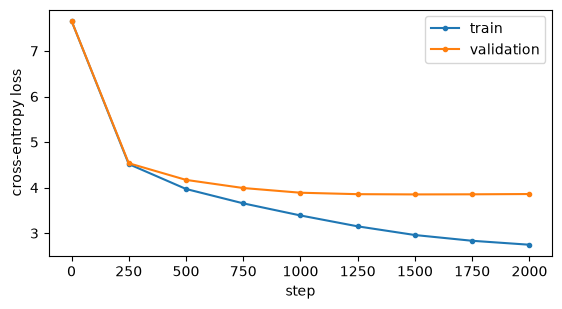

perplexity: start 2,128 -> best 47.0 (step 1500) -> final 47.4
final gap between validation and training loss: 1.113


In [6]:
steps_logged = [h[0] for h in history]
plt.figure(figsize=(6.5, 3.2))
plt.plot(steps_logged, [h[1] for h in history], marker=".", label="train")
plt.plot(steps_logged, [h[2] for h in history], marker=".", label="validation")
plt.xlabel("step")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.show()

final_train, final_val = history[-1][1], history[-1][2]
print(f"perplexity: start {math.exp(history[0][2]):,.0f} -> best {math.exp(best_val):.1f} (step {best_step}) -> final {math.exp(final_val):.1f}")
print(f"final gap between validation and training loss: {final_val - final_train:.3f}")

Both losses fall fast at first (7.66 → 4.5 in 250 steps). After about step 1,000 they separate: the training loss keeps falling to 2.75, but the validation loss stops improving at 3.85 (step 1,500) and starts creeping up, ending 1.1 above the training loss. With only 347,000 training tokens seen 23.6 times, the model starts memorizing Shakespeare's lines instead of learning more general patterns.

The best checkpoint (step 1,500, perplexity 47, down from 2,128 at the start) is the one kept. Real LLMs avoid this problem by having so much data that they see each token about once.

# 7. GENERATING TEXT: GREEDY, TEMPERATURE, TOP-K, TOP-P

Generation is a loop: feed the tokens so far, take the scores for the **last** position, pick one token, append it, repeat. How the token is picked matters a lot:

| Method | How it picks | Effect |
|---|---|---|
| greedy | always the highest-scoring token | deterministic, but often gets stuck repeating itself |
| temperature T | divide the logits by T, then sample | T < 1: safer and more repetitive; T > 1: more varied and more nonsense |
| top-k | sample only from the k most likely tokens | removes the long tail of bad tokens |
| top-p (nucleus) | sample from the smallest set of tokens whose probabilities add up to p | adapts: few candidates when the model is sure, many when it isn't |

Folder 07 covers decoding further (beam search, repetition penalties, the KV cache that makes this loop fast).

In [7]:
model.load_state_dict(best_state)


@torch.no_grad()
def generate(prompt: str, max_new_tokens: int = 60, temperature: float = 1.0, top_k: int | None = None, top_p: float | None = None) -> str:
    model.eval()
    ids = torch.tensor([tokenizer.encode(prompt).ids], device=device)
    for _ in range(max_new_tokens):
        logits = model(ids[:, -cfg.context:])[:, -1, :]            # scores for the next token only
        if temperature == 0:                                        # greedy
            next_id = logits.argmax(dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k is not None:
                kth_best = torch.topk(logits, top_k).values[:, -1:]
                logits = logits.masked_fill(logits < kth_best, float("-inf"))
            if top_p is not None:
                sorted_logits, order = logits.sort(descending=True)
                probs = sorted_logits.softmax(dim=-1)
                outside = probs.cumsum(dim=-1) - probs > top_p        # tokens after the nucleus is already full
                sorted_logits = sorted_logits.masked_fill(outside, float("-inf"))
                logits = torch.full_like(logits, float("-inf")).scatter(-1, order, sorted_logits)
            next_id = torch.multinomial(logits.softmax(dim=-1), num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    return tokenizer.decode(ids[0].tolist())


prompt = "ROMEO:\nWhat light"
for name, options in [("greedy", dict(temperature=0)), ("temperature 0.8, top-k 50", dict(temperature=0.8, top_k=50)),
                      ("top-p 0.9", dict(temperature=1.0, top_p=0.9)), ("temperature 1.5 (too random)", dict(temperature=1.5))]:
    torch.manual_seed(0)
    print(f"--- {name} ---\n{generate(prompt, **options)}\n")

--- greedy ---
ROMEO:
What light is the matter?

ROMEO:
I'll be a barn.

ROMEO:
I'll be a bitter: I will be a bawd.

ROMEO:
I'll be a bawd.

ROMEO:
I'll be a



--- temperature 0.8, top-k 50 ---
ROMEO:
What light is that?

ROMEO:
No, good night.

JULIET:
Arter, I can.

JULIET:
I do thee, the bottty ha!

Nurse:
Ay, ay, a hare, a very day,


--- top-p 0.9 ---
ROMEO:
What light is that?

ROMEO:
No, good night, the door's cloud.

MERCUTIO:
Too murderers; what world can weisely?

MERCUTIO:
O, I warrant thee: what?

MERCUTIO:
By this he was



--- temperature 1.5 (too random) ---
ROMEO:
What light being but revenge's another crown?
All whom dis posting the right in men clence drifester,--
We do in the devil endure yield into,
Lotten years:aking him holy master,
Lies Hastings'ones, and leave resc together, he give



From a 5-million-parameter model trained for 3 minutes:
- **Greedy** starts well, then repeats itself ("I'll be a bawd." again and again).
- **Temperature 0.8 with top-k 50**, and **top-p 0.9**, produce varied text in the right format: speaker names, short lines and Shakespearean words, though the meaning wanders.
- **Temperature 1.5** flattens the distribution so much that rare tokens get picked and the words fall apart ("clence drifester").

The model has learned spelling, format and style. Meaning and long-range coherence need far more parameters and data.

# 8. SAVING AND LOADING THE MODEL

A usable checkpoint needs three things: the weights, the config to rebuild the model, and **the tokenizer** (02.2 section 11).
A model is useless with a different tokenizer, because its embeddings are indexed by that tokenizer's ids.

In [8]:
MODEL_DIR.mkdir(exist_ok=True)
torch.save({"model": model.state_dict(), "config": asdict(cfg), "val_loss": best_val}, MODEL_DIR / "tiny_gpt.pt")
tokenizer.save(str(MODEL_DIR / "tiny_gpt_tokenizer.json"))

ckpt = torch.load(MODEL_DIR / "tiny_gpt.pt", map_location=device, weights_only=True)
restored = GPT(GPTConfig(**ckpt["config"])).to(device)
restored.load_state_dict(ckpt["model"])
restored_tokenizer = Tokenizer.from_file(str(MODEL_DIR / "tiny_gpt_tokenizer.json"))

original_text = generate(prompt, max_new_tokens=20, temperature=0)
model, tokenizer = restored, restored_tokenizer                     # generate() uses these globals
print("restored model + tokenizer give the same greedy text:", generate(prompt, max_new_tokens=20, temperature=0) == original_text)

restored model + tokenizer give the same greedy text: True


# 9. FROM THIS TOY TO A REAL LLM

| | This notebook | GPT-2 small (2019) | LLaMA 3 8B (2024) |
|---|---|---|---|
| parameters | 5.3M | 124M | 8B |
| layers × width | 6 × 256 | 12 × 768 | 32 × 4,096 |
| attention heads | 8 | 12 | 32 query heads, 8 key/value heads (grouped-query attention) |
| context | 128 tokens | 1,024 | 8,192 |
| vocabulary | 2,048 | 50,257 | 128,256 |
| training data | 1 MB of Shakespeare, about 20 passes | WebText, about 40 GB of web pages | about 15 trillion tokens, mostly a single pass |
| design | learned positions, LayerNorm, GELU | the same | RoPE, RMSNorm, SwiGLU |

What else changes at scale:
- **Data** becomes the main work: collecting, filtering, deduplicating and mixing trillions of tokens.
- **Compute:** training cost is about **6 × parameters × tokens** floating-point operations. This notebook: 6 × 5.3M × 8.2M tokens ≈ 2.6 × 10¹⁴ operations, a few minutes on a laptop GPU.
  The Chinchilla result suggests about 20 training tokens per parameter for compute-optimal training (folder 07); modern models train on far more,
  because a smaller model that has seen more data is cheaper to serve.
- **Engineering:** bf16 mixed precision, FSDP and tensor parallelism across thousands of GPUs, checkpointing and restarts (03.3).
- **After pre-training:** the model only continues text. Supervised fine-tuning and preference tuning (RLHF, DPO) turn it into an assistant that follows instructions (folders 07 and 13).

# 10. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Tokenizer | characters / small BPE / large BPE | characters: tiny embeddings, very long sequences. Small BPE: fine for one domain. Large BPE: shorter sequences and many languages, bigger embedding | large byte-level BPE for real LLMs |
| Output head | separate / tied to the embeddings | tied: fewer parameters, often better for small models. Separate: more flexibility for large models | tied for small models; many large LLMs untie |
| Context length | short / long | long: more context, quadratic attention cost and more memory | as long as the task needs and the budget allows |
| Model size vs data | bigger model / more tokens | for a fixed compute budget, both must grow; too big for the data overfits (section 6) | about 20 tokens per parameter or more |
| Passes over the data | many epochs / one pass | many: reuses scarce data, but overfits. One pass: no memorization, needs huge data | one pass for LLMs; a few epochs when data is limited |
| Decoding | greedy / temperature / top-k / top-p | greedy: deterministic, repetitive. Sampling: varied, can drift; top-p adapts to the model's confidence | temperature 0.7–1.0 with top-p 0.9–0.95 for creative text; greedy or low temperature for facts and code |
| Which weights to keep | last / best validation | best: protects against overfitting | best validation, as in this notebook |

# 11. INTERVIEW QUESTIONS

### Q1. How is a GPT trained, in 30 seconds?
It's a decoder-only transformer trained on next-token prediction. Each training window is shifted by one token to make the targets; the causal mask lets every position predict its next token in one forward pass,
and the loss is the average cross-entropy. Optimization is AdamW with warm-up, cosine decay and gradient clipping, over huge amounts of unlabelled text.

### Q2. What are teacher forcing and exposure bias?
During training the model is always given the true previous tokens (teacher forcing), which makes training parallel and stable. At generation time it conditions on its own outputs,
which it never saw in training, so early mistakes can push it off course (exposure bias).

### Q3. What is perplexity?
The exponential of the average cross-entropy loss: roughly the number of equally likely tokens the model is choosing between. Lower is better. An untrained model has perplexity close to the vocabulary size.

### Q4. What loss do you expect at initialization, and why check it?
About ln(vocabulary size), because a fresh model with small weights predicts roughly uniformly. A very different value points to a bug in the loss, the targets or the initialization (section 4).

### Q5. What is weight tying?
Using the token-embedding matrix as the output layer's weights. Input and output both map between tokens and the same vector space, so sharing saves `vocabulary × d_model` parameters and often improves small models.

### Q6. Greedy vs temperature vs top-k vs top-p sampling?
Greedy always picks the most likely token: deterministic but prone to loops. Temperature rescales the logits before sampling (lower is safer, higher more diverse).
Top-k samples from the k most likely tokens; top-p from the smallest set whose probabilities sum to p, adapting to the model's confidence.

### Q7. Why does greedy decoding repeat itself?
Once a phrase appears, it becomes the most likely continuation of itself; always taking the argmax keeps choosing it, so the text falls into loops (section 7).
Sampling, repetition penalties or beam search with n-gram blocking reduce this.

### Q8. Why is generation slower than training, per token?
Training processes all positions of a window in parallel. Generation is sequential: each new token needs a forward pass that depends on the previous one.
The KV cache avoids recomputing keys and values for earlier tokens, but each step still waits for the last (folder 07).

### Q9. How do you tell that a language model is overfitting, and why do large LLMs train for only about one epoch?
Training loss keeps falling while validation loss flattens and rises (section 6). LLMs have so much data that one pass is affordable; repeating data leads to memorization and wastes compute
that could see new text.

### Q10. Why initialize weights with a small standard deviation like 0.02?
Small weights keep the initial logits near zero (uniform predictions) and the activations in a stable range through the residual stream. GPT-2 additionally scales the residual output projections by 1/√(2 · layers)
so the sum over many blocks doesn't grow with depth.

### Q11. How much compute does training a transformer take?
About 6 × N × D floating-point operations for N parameters and D training tokens (2 for the forward pass, 4 for the backward pass). Compute-optimal training (Chinchilla) uses about 20 tokens per parameter;
production models often train much longer to get a smaller, cheaper-to-serve model.

### Q12. What separates this tiny GPT from a production LLM?
Scale (billions of parameters, trillions of tokens), data pipelines (filtering, deduplication, mixing), architecture updates (RoPE, RMSNorm, SwiGLU, grouped-query attention),
distributed bf16 training, long context, and post-training (supervised fine-tuning and RLHF or DPO) to make it follow instructions safely.

# 12. IN MY OWN WORDS

Write this from memory, without looking above:

- How the inputs and targets of a training window are built:
- The parts of the GPT model, from token ids to logits:
- The training recipe (optimizer, schedule, clipping, which weights to keep):
- Greedy vs temperature vs top-k vs top-p:
- What changes when going from this model to a real LLM: